## Part 1: HST Calibration

In [211]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import os

#### Loading Calibration Files

In [212]:
path = 'hst-data/calibration'
for folder in ['ubai2505m', 'ubai2507m', 'ubai2508m']:
    print(folder)
    print(os.listdir(os.path.join(path, folder)))

ubai2505m
['ubai2505m_atodfile.fits', 'ubai2505m_flatfile.fits', 'ubai2505m_raw.fits', 'ubai2505m_blevfile.fits', 'ubai2505m_maskfile.fits', 'ubai2505m_biasfile.fits', 'ubai2505m_darkfile.fits']
ubai2507m
['ubai2507m_flatfile.fits', 'ubai2507m_atodfile.fits', 'ubai2507m_darkfile.fits', 'ubai2507m_biasfile.fits', 'ubai2507m_maskfile.fits', 'ubai2507m_blevfile.fits', 'ubai2507m_raw.fits']
ubai2508m
['ubai2508m_atodfile.fits', 'ubai2508m_flatfile.fits', 'ubai2508m_raw.fits', 'ubai2508m_biasfile.fits', 'ubai2508m_darkfile.fits', 'ubai2508m_blevfile.fits', 'ubai2508m_maskfile.fits']


### 1. Working with ubai2505m first

In [213]:
#inspecting one raw image 
image1 = fits.open('hst-data/calibration/ubai2505m/ubai2505m_raw.fits')
image1.info()

Filename: hst-data/calibration/ubai2505m/ubai2505m_raw.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     190   ()      
  1  SCI           1 ImageHDU        12   (800, 800, 4)   int16   


In [214]:
print(image1[0].header)

SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                    8 / array data type                                NAXIS   =                    0 / number of array dimensions                     EXTEND  =                    T                                                  NEXTEND =                    4 / Number of standard extensions                  DATE    = '2009-07-22'         / date this file was written (yyyy-mm-dd)        FILENAME= 'ubai2505m.d0f                          ' / name of file              FILETYPE= 'SCI      '          / type of data found in data file                                                                                                TELESCOP= 'HST'                / telescope used to acquire data                 INSTRUME= 'WFPC2 '             / identifier for instrument used to acquire data EQUINOX =               2000.0 / equinox of celestial coord. system                                                     

In [215]:
#getting data out of .fits file
pixels1 = image1[1].data
#extracting header
header1 = image1[1].header
print('image shape =', np.shape(pixels1))
print(header1)

image shape = (4, 800, 800)
XTENSION= 'IMAGE   '           / Image extension                                BITPIX  =                   16 / array data type                                NAXIS   =                    3 / number of array dimensions                     NAXIS1  =                  800                                                  NAXIS2  =                  800                                                  NAXIS3  =                    4                                                  PCOUNT  =                    0 / number of parameters                           GCOUNT  =                    1 / number of groups                               EXTNAME = 'SCI     '                                                            EXTVER  =                    1                                                  BUNIT   = 'DN      '                                                            COMMENT Axis mapts to [0: PC1, 1: WF2, 2: WF3, 3: WF4]                          END         

#### Inspecting the mask file

In [216]:
maskfile = fits.open('hst-data/calibration/ubai2505m/ubai2505m_maskfile.fits')
maskfile.info()

Filename: hst-data/calibration/ubai2505m/ubai2505m_maskfile.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     217   (800, 800, 4)   int16   
  1  f8213081u.r0h.tab    1 TableHDU       162   4R x 38C   [D25.16, D25.16, E15.7, E15.7, E15.7, E15.7, E15.7, E15.7, E15.7, E15.7, A4, E15.7, I11, I11, D25.16, D25.16, A8, A8, I11, E15.7, E15.7, E15.7, E15.7, E15.7, E15.7, I11, I11, I11, I11, I11, I11, I11, I11, A48, E15.7, E15.7, E15.7, E15.7]   


In [217]:
#extracting data from mask file
mask1 = maskfile[0].data
# ensuring shaope is valid at [0]
print("shape = ", np.shape(mask1))
# inspecting data 
print('vals=', np.unique(mask1))

shape =  (4, 800, 800)
vals= [  0   2 256]


### a. masking invalid data

In [218]:
# 2 represents defective pixels - replace every 2 with NaN
pixels1a = np.where(mask1==2, np.nan, pixels1) 

### b. removing bias level

In [219]:
#loading and inspecting blevfile - bias level
blevfile1 = fits.open('hst-data/calibration/ubai2505m/ubai2505m_blevfile.fits')
blevfile1.info()

Filename: hst-data/calibration/ubai2505m/ubai2505m_blevfile.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      46   ()      
  1  EXT           1 ImageHDU        27   (14, 800)   int16   
  2  EXT           2 ImageHDU        27   (14, 800)   int16   
  3  EXT           3 ImageHDU        27   (14, 800)   int16   
  4  EXT           4 ImageHDU        27   (14, 800)   int16   


In [220]:
pixels1b = pixels1a.copy()
for i in range(4):
    #extracting data from each blevfile
    blev = blevfile1[i+1].data 
    print('shape =', np.shape(blev), "for chip", i)
    odd_vals = blev[9:790, 8:14:2]
    even_vals = blev[9:790, 9:14:2]
    odd_bias = np.mean(odd_vals)
    even_bias = np.mean(even_vals)
    print("Odd bias = ", odd_bias, "for chip", i)
    print("Even bias =", even_bias, 'for chip', i)
    pixels1b[i, :, 0::2] = pixels1a[i, :, 0::2] - odd_bias  
    pixels1b[i, :, 1::2] = pixels1a[i, :, 1::2] - even_bias 

shape = (800, 14) for chip 0
Odd bias =  299.58472044387537 for chip 0
Even bias = 299.59154929577466 for chip 0
shape = (800, 14) for chip 1
Odd bias =  319.96030729833547 for chip 1
Even bias = 319.93341869398205 for chip 1
shape = (800, 14) for chip 2
Odd bias =  313.48314127187365 for chip 2
Even bias = 313.46478873239437 for chip 2
shape = (800, 14) for chip 3
Odd bias =  298.7443448570209 for chip 3
Even bias = 298.74989329918907 for chip 3


### c. Image Calibration

In [221]:
#loading bias, dark and flat
#loading bias, dark and flat
biasfile1 = fits.open('hst-data/calibration/ubai2505m/ubai2505m_biasfile.fits')   
darkfile1 = fits.open('hst-data/calibration/ubai2505m/ubai2505m_darkfile.fits')  
flatfile1 = fits.open('hst-data/calibration/ubai2505m/ubai2505m_flatfile.fits')  

In [223]:
# inspecting files
biasfile1.info()
darkfile1.info()
flatfile1.info()

Filename: hst-data/calibration/ubai2505m/ubai2505m_biasfile.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     233   (800, 800, 4)   float32   
  1  t7d1506ou_cvt.r2h.tab    1 TableHDU       276   4R x 38C   [D25.17, D25.17, E15.7, E15.7, E15.7, E15.7, E15.7, E15.7, E15.7, E15.7, A1, E15.7, I12, I12, D25.17, D25.17, A8, A8, I12, E15.7, E15.7, E15.7, E15.7, E15.7, E15.7, I12, I12, I12, I12, I12, I12, I12, I12, A48, E15.7, E15.7, E15.7, E15.7]   
Filename: hst-data/calibration/ubai2505m/ubai2505m_darkfile.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     370   (800, 800, 4)   float32   
  1  t721745gu_cvt.r3h.tab    1 TableHDU       276   4R x 38C   [D25.17, D25.17, E15.7, E15.7, E15.7, E15.7, E15.7, E15.7, E15.7, E15.7, A1, E15.7, I12, I12, D25.17, D25.17, A8, A8, I12, E15.7, E15.7, E15.7, E15.7, E15.7, E15.7, I12, I12, I12, I12, I12, I12, I12, I12, A48, E15.7, E15.7, E15.7, E15.7]  

In [224]:
#extracting data from files 
bias1 = biasfile1[0].data 
dark1 = darkfile1[0].data 
flat1= flatfile1[0].data 
#checking shape of eacgh file 
print(np.shape(bias1), np.shape(dark1), np.shape(flat1))

(4, 800, 800) (4, 800, 800) (4, 800, 800)


In [225]:
#checking flat values
print('flat min, mean, max =', np.nanmin(flat1), np.nanmean(flat1), np.nanmax(flat1))
print('zeros in flat =', np.sum(flat1 == 0), ' nans in flat =', np.sum(np.isnan(flat1)))

flat min, mean, max = 0.009630168 5.6277857 150.95598
zeros in flat = 0  nans in flat = 0


In [238]:
#dark needs to be. multiplied by ex[osure time - extract from header 
exptime = image1[0].header['EXPTIME']
print(exptime)
#calibrating image from formula - flat is inverse semsitivity - mutiply not divide 
pixels1c = pixels1b - bias1
pixels1c = pixels1c - (exptime*dark1)
pixels1c = pixels1c * flat1

700.0


### d. subtracting sky counts - taken as median pixels 

In [239]:
# subtracting sky counts - reasonable assumption - median counts of images 
pixels1d = pixels1c.copy()
for i in range(4):
    sky = np.nanmedian(pixels1c[i])
    print("Sky =", sky, 'for chip', i)
    pixels1d[i] = pixels1c[i] - sky

Sky = 0.7616675692936031 for chip 0
Sky = 0.44809097416617655 for chip 1
Sky = 0.06713016129627093 for chip 2
Sky = 0.7055080211580341 for chip 3


### e. plotting calibrated image

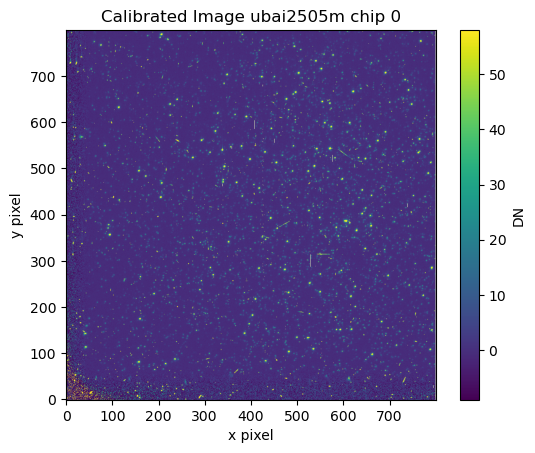

In [240]:
img = pixels1d[0]
vmin, vmax = np.nanpercentile(img, [1, 99.5])
plt.imshow(img, origin='lower', vmin=vmin, vmax=vmax)
plt.colorbar(label='DN')
plt.title("Calibrated Image ubai2505m chip 0")
plt.xlabel("x pixel")
plt.ylabel("y pixel")
plt.show()

### e. photometry calibration

In [241]:
# checking photometry calibration values in science-ready images
f336w_file = fits.open('hst-data/F336W/ubai2505m_c0m_aligned.fits')
f336w_header = f336w_file['SCI'].header
photflam = f336w_header['PHOTFLAM']
photzpt = f336w_header['PHOTZPT']
zp_corr = f336w_header['ZP_CORR']
print(photflam, photzpt, zp_corr)

1.115396e-16 -21.1 -0.03288031


In [261]:
#calcuklating the flux 
countrate = pixels1d/exptime
flux1 = countrate*photflam

In [262]:
#calculating apparant magnitude from flux 
mag1 = np.full(flux1.shape, np.nan)
positive = np.isfinite(flux1) & (flux1 > 0)
mag1[positive] = -2.5*np.log10(flux1[positive]) + photzpt